## MC Bootstrap

number of iterations 49
asteroid distance error: 2.0324604915618423 %
r_vec_ec [ 0.01825552 -1.43278497  0.2911823 ] [ 0.07085849 -1.40590156  0.3095287 ] [ 0.13505932 -1.36989693  0.33128928]
r2_vec_actual, v2_vec_actual [ 0.06597709 -1.41498321  0.31602103] [0.01288135 0.00690263 0.00459475]
v2_vec_ec [0.01297132 0.00691383 0.0044678 ]
f1, g1, f3, g3 0.9992003466625444 -0.06968505196435804 0.9987635423731905 0.08525703466875946
% error r2_vec 0.6910416185366088 %
% error v2_vec 0.2829622434697444 %
Orbital Elements: 1.6948297059308517 0.3634526139925629 26.158527229541924 246.2902145409585 115.90945120209128 341.1741085913194
Expected Orbital Elements: 1.709375875200247 0.3648329026171276 26.86986395245218 246.5733908423288 115.4656355507939 313.4881025916907
Orbital Elements error %: 0.8509637628816604 0.378334468920755 2.6473402476804857 0.11484463120815046 0.3843703359707693 8.831597043313938
number of iterations 50
asteroid distance error: 2.8955878047896437 %
r_vec_ec [ 0.020189

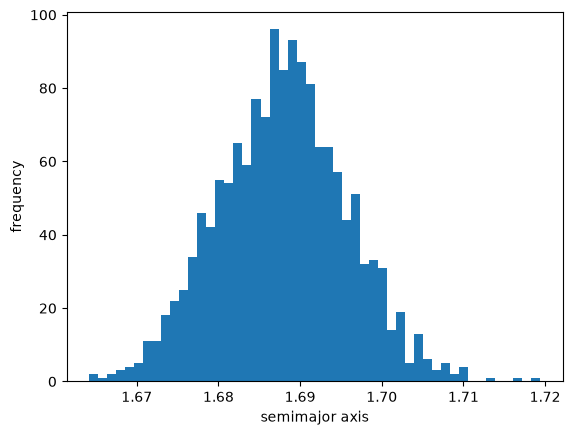

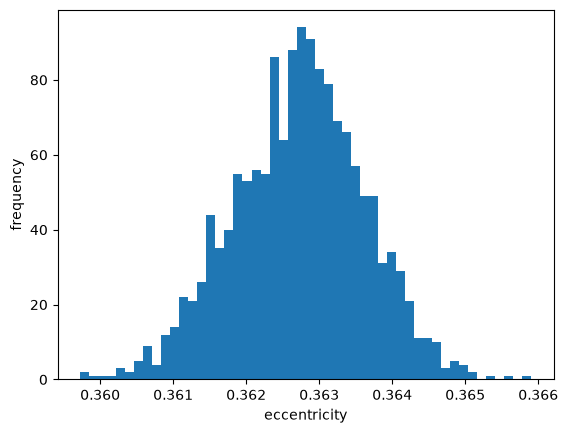

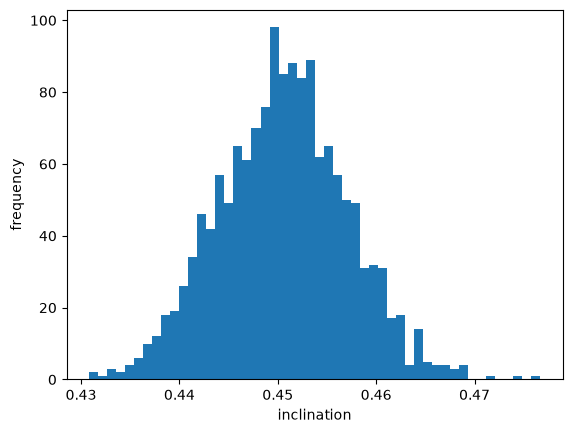

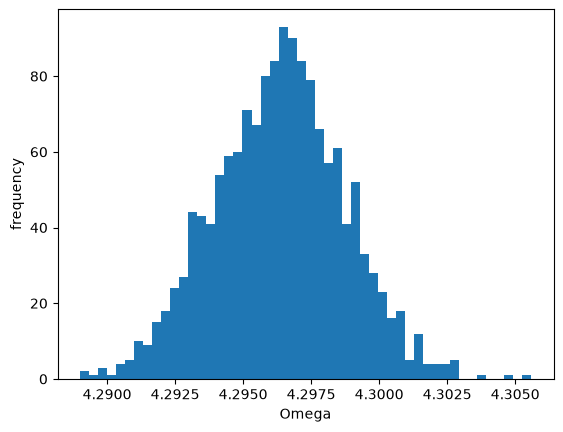

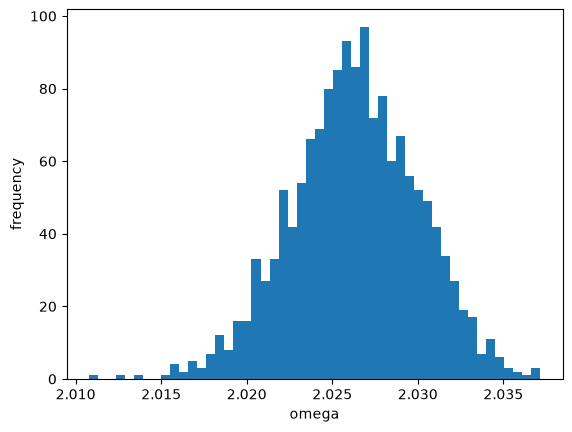

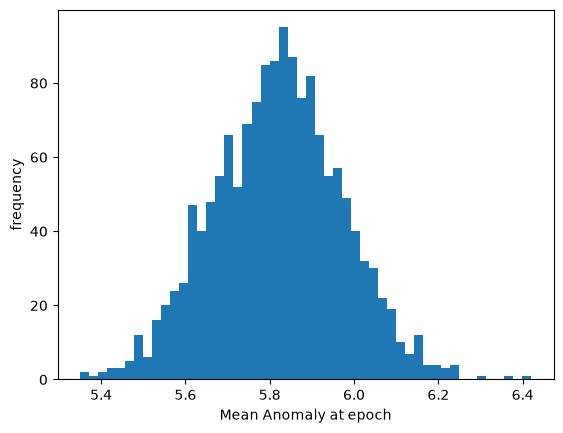

In [2]:
import numpy as np
from importlib import reload
import Zhu_OD_Actual
import Zhu_odlib
import matplotlib.pyplot as plt
reload(Zhu_odlib)
reload(Zhu_OD_Actual)

#get the times
t1 = 2461227.6979167 
t2 = 2461231.7500000 
t3 = 2461236.7083333
t4 = 2461240.6666667

t1_const = 2461227.6979167 
t2_const = 2461231.7500000 
t3_const = 2461236.7083333
t0 = 2461231.7500000
t4_const = 2461240.6666667

# ra1_rad = np.deg2rad(246.864008)
# dec1_rad = np.deg2rad(8.96303333)
# ra2_rad = np.deg2rad(245.633742)
# dec2_rad = np.deg2rad(10.8217722)
# ra3_rad = np.deg2rad(244.40145)
# dec3_rad = np.deg2rad(12.8442111)
# ra4_rad = np.deg2rad(243.684262)
# dec4_rad = np.deg2rad(14.2092056)
ra1_rad = np.deg2rad(246.866541667)
dec1_rad = np.deg2rad(8.95958333333)
ra2_rad = np.deg2rad(245.6305)
dec2_rad = np.deg2rad(10.8265277778)
ra3_rad = np.deg2rad(244.412666667)
dec3_rad = np.deg2rad(12.8259166667)


#get R_sun_vec in ecliptic coordinates values in AU/day
r2_vec_actual = np.array([6.597708943023856E-02, -1.414983210141008E+00, 3.160210310129223E-01])
v2_vec_actual = np.array([1.288134902030575E-02, 6.902634010416600E-03, 4.594750177786959E-03])
pos_ast_actual = np.array([-2.423378396237330E-01, -4.462283685152122E-01, 3.159296182543370E-01])
r3_vec_actual = np.array([1.297412592280285E-01, -1.379058202090238E+00, 3.384113720032870E-01])
v3_vec_actual = np.array([1.283298624441365E-02, 7.591267178834147E-03, 4.433381037843229E-03])


pos3_ast_actual = np.array([-2.573482620789715E-01, -4.391763079544195E-01, 3.383202185382085E-01])

#get orbital elements in degrees
a_actual = 1.709375875200247    
e_actual = 0.3648329026171276   
i_actual = 26.86986395245218
Omega_actual = 246.5733908423288   
omega_actual = 115.4656355507939   
M0_actual = 3.134881025916907E+02

#Units are in AU and days (from observations)
R_sun_vec1 = np.array([-2.423315750408254E-01, 9.873394152864740E-01, -5.667175240168493E-05])
R_sun_vec2 = np.array([-3.083053310421857E-01, 9.687376207018604E-01, -5.367674882323271E-05])
R_sun_vec3 = np.array([-3.870854813412044E-01, 9.398635835173186E-01, -5.292927887796023E-05])
R_sun_vec4 = np.array([-4.486973102323266E-01, 9.117911989410320E-01, -5.346925197728322E-05])
# asteroid RA measured on 10 images through one night (it really moves)

ra  = np.array([ra1_rad, ra2_rad, ra3_rad])    
dec  = np.array([dec1_rad, dec2_rad, dec3_rad])

delta_ra = np.array([np.deg2rad(15*9.048621750889196e-07), np.deg2rad(15*4.874628193894978e-06), np.deg2rad(15*4.286542311958866e-05)])
delta_dec = np.array([np.deg2rad(1.7153324669450914e-05), np.deg2rad(1.592080399836959e-06), np.deg2rad(6.596400533652699e-06)])
n, N = len(ra), 1500
orbital_elements = []
for k in range(N):
    ran_ra1_k = ra[0] + np.random.normal(0, delta_ra[0])
    ran_dec1_k = dec[0] + np.random.normal(0, delta_dec[0])
    ran_ra2_k = ra[1] + np.random.normal(0, delta_ra[1])
    ran_dec2_k = dec[1] + np.random.normal(0, delta_dec[1])
    ran_ra3_k = ra[2] + np.random.normal(0, delta_ra[2])
    ran_dec3_k = dec[2] + np.random.normal(0, delta_dec[2])
    values = Zhu_OD_Actual.get_od_elements(t1, t2, t3, t1_const, t2_const, t3_const, ran_ra1_k, ran_dec1_k, ran_ra2_k, ran_dec2_k, ran_ra3_k,ran_dec3_k, r2_vec_actual, v2_vec_actual, a_actual, e_actual,i_actual, Omega_actual, omega_actual, M0_actual, R_sun_vec1, R_sun_vec2, R_sun_vec3)                                                                     
    orbital_elements.append(values)
orbital_elements = np.array(orbital_elements)
print("monte carlo finished!!!")
names = ['a', 'e', 'I', 'Omega', 'omega', 'M0']
for j in range(6):
    lo = np.percentile(orbital_elements[:,j], 16)
    med = np.percentile(orbital_elements[:,j], 50)
    hi = np.percentile(orbital_elements[:,j], 84)
    print({names[j]})
    print({lo})
    print({med})
    print({hi})
    print({hi - med})
    print({med - lo})

plt.hist(orbital_elements[:,0], bins = 50)
plt.xlabel("semimajor axis")
plt.ylabel("frequency")
plt.show()

plt.hist(orbital_elements[:,1], bins = 50)
plt.xlabel("eccentricity")
plt.ylabel("frequency")
plt.show()

plt.hist(orbital_elements[:,2], bins = 50)
plt.xlabel("inclination")
plt.ylabel("frequency")
plt.show()

plt.hist(orbital_elements[:,3], bins = 50)
plt.xlabel("Omega")
plt.ylabel("frequency")
plt.show()

plt.hist(orbital_elements[:,4], bins = 50)
plt.xlabel("omega")
plt.ylabel("frequency")
plt.show()

plt.hist(orbital_elements[:,5], bins = 50)
plt.xlabel("Mean Anomaly at epoch")
plt.ylabel("frequency")
plt.show()

## Jackknife

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import Zhu_odlib
import Zhu_OD_Actual
reload(Zhu_OD_Actual)

#get the times
t1 = 2461227.6979167 
t2 = 2461231.7500000 
t3 = 2461236.7083333
t4 = 2461240.6666667

t1_const = 2461227.6979167 
t2_const = 2461231.7500000 
t3_const = 2461236.7083333
t0 = 2458473.5 
t4_const = 2461240.6666667

ra1_rad = np.deg2rad(246.864008)
dec1_rad = np.deg2rad(8.96303333)
ra2_rad = np.deg2rad(245.633742)
dec2_rad = np.deg2rad(10.8217722)
ra3_rad = np.deg2rad(244.40145)
dec3_rad = np.deg2rad(12.8442111)
ra4_rad = np.deg2rad(243.684262)
dec4_rad = np.deg2rad(14.2092056)

#get R_sun_vec in ecliptic coordinates values in AU/day
r2_vec_actual = np.array([6.597708943023856E-02, -1.414983210141008E+00, 3.160210310129223E-01])
v2_vec_actual = np.array([1.288134902030575E-02, 6.902634010416600E-03, 4.594750177786959E-03])
pos_ast_actual = np.array([-2.423378396237330E-01, -4.462283685152122E-01, 3.159296182543370E-01])

#get orbital elements in degrees
a_actual = 1.709375875200247    
e_actual = 0.3648329026171276   
i_actual = 26.86986395245218
Omega_actual = 246.5733908423288   
omega_actual = 115.4656355507939   
M0_actual = 177.208859195229    

#Units are in AU and days (from observations)
R_sun_vec1 = np.array([-2.423315750408254E-01, 9.873394152864740E-01, -5.667175240168493E-05])
R_sun_vec2 = np.array([-3.083053310421857E-01, 9.687376207018604E-01, -5.367674882323271E-05])
R_sun_vec3 = np.array([-3.870854813412044E-01, 9.398635835173186E-01, -5.292927887796023E-05])
R_sun_vec4 = np.array([-4.486973102323266E-01, 9.117911989410320E-01, -5.346925197728322E-05])
t  = np.array([0.00, 0.11, 0.19, 0.28, 0.36, 0.47, 0.55, 0.66, 0.74, 0.83])   # hours
ra = np.array([142.031, 142.038, 142.041, 142.047, 142.050,
               142.058, 142.061, 142.068, 142.070, 142.078])                  # deg

def rate(t, ra):
    return np.polyfit(t, ra, 1)[0]        # slope = RA drift (deg/hr)

n = len(t)
jack = np.array([rate(np.delete(t, i), np.delete(ra, i))   # drop image i, refit
                 for i in range(n)])

abar = jack.mean()                                    # best estimate
se   = np.sqrt((n-1)/n * np.sum((jack - abar)**2))    # jackknife error
print(f"RA rate = {abar:.4f} +/- {se:.4f} deg/hr")